# Understanding the OGBN-Arxiv dataset

**What this notebook does:** it looks at the dataset before we do any machine learning.

**Why:** if we do not know the data, we cannot explain our results later. So first we study the
graph. Training comes in the experiment notebook.

**What we will find out:**

- What is a node? What is an edge?
- How many nodes, edges, classes?
- What do the node features look like?
- How are the labels spread?
- What are the train / validation / test splits?
- Is the graph directed?
- What are the node degrees?
- Is the graph connected?
- Do connected papers usually have the same label? (this is called *homophily*)

At the end we save all the numbers to a file, so the experiment notebook can use them.

## Install and import

Run this on Google Colab. The first cell installs two libraries:

- `ogb` — gives us the dataset
- `torch_geometric` — we do not need it here, but the experiment notebook does

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q ogb torch_geometric

print("Colab:", IN_COLAB)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 30.3 MB/s eta 0:00:00
Colab: True


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ogb
print("NumPy :", np.__version__)
print("OGB   :", ogb.__version__)

NumPy : 2.1.3
OGB   : 1.3.6


## Look at the OGB library before using it

We do not know this library well. So before loading the dataset, we just *look* at what is inside.

In OGB version 1.3.6 the loader is called `NodePropPredDataset`.
There is also `PygNodePropPredDataset`, but we are **not** using it.

In [3]:
import ogb.nodeproppred as npp

print("Things inside ogb.nodeproppred:")
print([name for name in dir(npp) if not name.startswith("_")])

Things inside ogb.nodeproppred:
['Evaluator', 'NodePropPredDataset', 'PygNodePropPredDataset', 'dataset', 'dataset_pyg', 'evaluate']


### A small fix before loading

OGB saves the prepared dataset using PyTorch. New versions of PyTorch refuse to open such a file
unless we say we trust it. The two lines below tell PyTorch that this file is fine.

Without this, the dataset loads the first time (when it is downloaded) but fails the **second**
time (when it is read from the saved folder).

In [4]:
import torch

# OGB saves its prepared data with torch.save. Newer PyTorch needs weights_only=False to read it.
_original_load = torch.load
def _load_ogb_file(*args, **kwargs):
    kwargs["weights_only"] = False
    return _original_load(*args, **kwargs)
torch.load = _load_ogb_file

print("ready to load the dataset")

ready to load the dataset


## Load the dataset

The first run downloads about 80 MB. After that it loads from the folder `./data`.

In [5]:
from ogb.nodeproppred import NodePropPredDataset

dataset = NodePropPredDataset(name="ogbn-arxiv", root="./data")

print("type of dataset :", type(dataset))
print("len(dataset)    :", len(dataset))
print("type(dataset[0]):", type(dataset[0]))

Downloaded 0.08 GB: 100%|██████████| 81/81 [00:05<00:00, 13.51it/s]


Extracting ./data/arxiv.zip
Loading necessary files...
This might take a while.
Processing graphs...


100%|██████████| 1/1 [00:00<00:00, 10672.53it/s]

Saving...


type of dataset : <class 'ogb.nodeproppred.dataset.NodePropPredDataset'>
len(dataset)    : 1
type(dataset[0]): <class 'tuple'>


`len(dataset)` is 1. That is because OGBN-Arxiv is **one big graph**, not many small graphs.

`dataset[0]` is a *tuple*. Let us open it and see what is inside.

In [6]:
graph, labels = dataset[0]      # first part = graph, second part = labels

print("keys inside graph:", list(graph.keys()))
print()
for key in graph:
    value = graph[key]
    if isinstance(value, np.ndarray):
        print(f"  {key:12s} shape = {value.shape}, dtype = {value.dtype}")
    else:
        print(f"  {key:12s} = {value}")

print()
print("labels shape:", labels.shape, " dtype:", labels.dtype)

keys inside graph: ['edge_index', 'edge_feat', 'node_feat', 'node_year', 'num_nodes']

  edge_index   shape = (2, 1166243), dtype = int64
  edge_feat    = None
  node_feat    shape = (169343, 128), dtype = float32
  node_year    shape = (169343, 1), dtype = int64
  num_nodes    = 169343

labels shape: (169343, 1)  dtype: int64


Now we understand the structure:

| name | shape | meaning |
|---|---|---|
| `edge_index` | `[2, E]` | the list of edges |
| `node_feat` | `[N, 128]` | 128 numbers describing each paper |
| `node_year` | `[N, 1]` | year the paper was published |
| `edge_feat` | `None` | this dataset has no edge features |
| `labels` | `[N, 1]` | one class number per paper |

## Basic numbers

- A **node** is one Computer Science paper from arXiv.
- An **edge** `u -> v` means "paper u cites paper v".
- The **label** is the subject area of the paper (like cs.LG, cs.CV). There are 40 subjects.

In [7]:
edge_index = graph["edge_index"]
features = graph["node_feat"]
years = graph["node_year"].reshape(-1)     # reshape(-1) makes the shape [N,1] into [N]

num_nodes = int(graph["num_nodes"])
num_edges = int(edge_index.shape[1])
num_features = int(features.shape[1])
num_classes = int(labels.max()) + 1        # classes are 0,1,2,...,39 so max + 1 = 40

print("Nodes (papers)   :", f"{num_nodes:,}")
print("Edges (citations):", f"{num_edges:,}")
print("Features per node:", num_features)
print("Number of classes:", num_classes)

Nodes (papers)   : 169,343
Edges (citations): 1,166,243
Features per node: 128
Number of classes: 40


## What is `edge_index`?

`edge_index` has shape `[2, E]`. Each **column** is one edge.

- `edge_index[0]` = the **source** node (the paper that cites)
- `edge_index[1]` = the **target** node (the paper being cited)

**Why store edges like this?** The other option is a big N x N table (adjacency matrix).
For 169,343 nodes that table would need about 28 billion boxes, and almost all of them would be
zero. The edge list only stores the edges that really exist. That is much smaller.

In [8]:
print("First 6 columns of edge_index:")
print(edge_index[:, :6])
print()
for i in range(4):
    u = edge_index[0, i]
    v = edge_index[1, i]
    print(f"  column {i}: paper {u} cites paper {v}")

First 6 columns of edge_index:
[[104447  15858 107156 107156 107156 107156]
 [ 13091  47283  69161 136440 107366 158460]]

  column 0: paper 104447 cites paper 13091
  column 1: paper 15858 cites paper 47283
  column 2: paper 107156 cites paper 69161
  column 3: paper 107156 cites paper 136440


In [9]:
source = edge_index[0].astype(np.int64)
target = edge_index[1].astype(np.int64)

print("sources (edge_index[0]):", source[:6])
print("targets (edge_index[1]):", target[:6])

sources (edge_index[0]): [104447  15858 107156 107156 107156 107156]
targets (edge_index[1]): [ 13091  47283  69161 136440 107366 158460]


## Node features

Each paper has 128 numbers. These numbers come from the **words in the title and abstract**.
The words are turned into vectors (word2vec) and then averaged.

So the features tell us about the *text* of the paper. They say nothing about the graph.
That is good for us — it means the graph can add extra information.

We also check for NaN and Inf values. Even one bad value can break training later.

In [10]:
print("Feature matrix shape:", features.shape)
print("dtype               :", features.dtype)
print("NaN values          :", int(np.isnan(features).sum()))
print("Inf values          :", int(np.isinf(features).sum()))
print()
print("min  :", round(float(features.min()), 4))
print("max  :", round(float(features.max()), 4))
print("mean :", round(float(features.mean()), 4))
print("std  :", round(float(features.std()), 4))
print()
print("Small sample (3 papers, first 6 numbers):")
print(np.round(features[:3, :6], 3))

Feature matrix shape: (169343, 128)
dtype               : float32
NaN values          : 0
Inf values          : 0

min  : -1.3889
max  : 1.6387
mean : 0.0205
std  : 0.2332

Small sample (3 papers, first 6 numbers):
[[-0.058 -0.053 -0.073 -0.027  0.13  -0.241]
 [-0.124 -0.071 -0.325  0.008 -0.002  0.074]
 [-0.08  -0.023 -0.184 -0.181  0.076 -0.126]]


The numbers are small and centred near zero. That is normal for averaged word vectors.
So we do **not** do any extra scaling. Adding extra steps without a reason would only make our
experiment harder to explain.

## Labels

Let us see how many papers belong to each class.

In [11]:
y = labels.reshape(-1)           # from shape [N,1] to shape [N]

print("smallest label:", int(y.min()))
print("largest label :", int(y.max()))
print("how many different labels:", len(np.unique(y)))

# np.bincount counts how many times each class number appears
class_counts = np.bincount(y, minlength=num_classes)

class_table = pd.DataFrame({
    "class": np.arange(num_classes),
    "papers": class_counts,
    "percent": np.round(100 * class_counts / num_nodes, 2),
})

print()
print("5 biggest classes:")
print(class_table.sort_values("papers", ascending=False).head(5).to_string(index=False))
print()
print("5 smallest classes:")
print(class_table.sort_values("papers").head(5).to_string(index=False))

smallest label: 0
largest label : 39
how many different labels: 40

5 biggest classes:
 class  papers  percent
    16   27321    16.13
    24   22187    13.10
    28   21406    12.64
    30   11814     6.98
    10    7869     4.65

5 smallest classes:
 class  papers  percent
    12      29     0.02
    35     127     0.07
    21     393     0.23
    15     403     0.24
    32     411     0.24


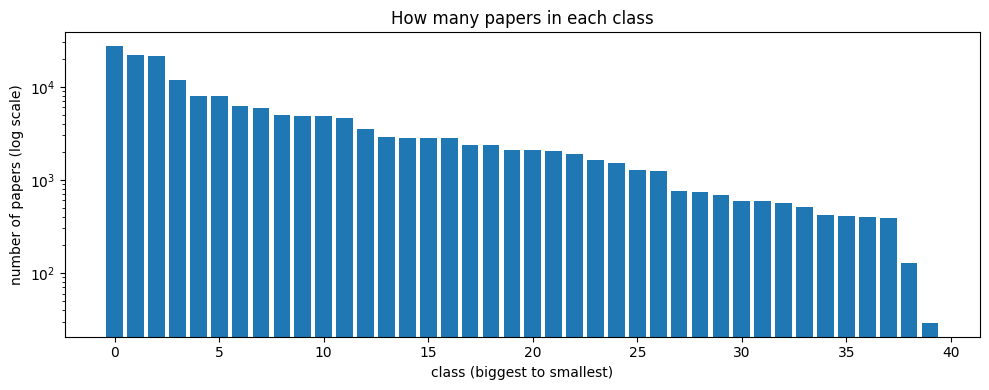

Biggest class has 27321 papers
Smallest class has 29 papers


In [12]:
order = np.argsort(-class_counts)         # sort classes from big to small

plt.figure(figsize=(10, 4))
plt.bar(range(num_classes), class_counts[order])
plt.yscale("log")                        # log scale, because the sizes are very different
plt.xlabel("class (biggest to smallest)")
plt.ylabel("number of papers (log scale)")
plt.title("How many papers in each class")
plt.tight_layout()
plt.show()

print("Biggest class has", class_counts.max(), "papers")
print("Smallest class has", class_counts.min(), "papers")

**What this means:** the classes are very **unbalanced**. Some subjects have many papers, some
have very few.

We will still use **accuracy** in the experiment notebook, because that is the official metric for this dataset.
But remember: accuracy mostly measures how well we do on the big classes.

A useful baseline: if we always guess the biggest class, we already get some accuracy for free.
We print that number below. Our models must beat it.

In [13]:
print("Random guessing accuracy  :", round(1 / num_classes, 4))
print("Always-biggest-class       :", round(class_counts.max() / num_nodes, 4))

Random guessing accuracy  : 0.025
Always-biggest-class       : 0.1613


## Train / validation / test split

OGB already gives us a fixed split. We will **keep it**. We will not make our own random split.

- **train** — we learn from these labels
- **validation** — we use these to choose the best epoch
- **test** — we look at these only once, at the very end

In [14]:
split = dataset.get_idx_split()

print("keys:", list(split.keys()))

train_idx = split["train"]
valid_idx = split["valid"]
test_idx = split["test"]

rows = []
for name, idx in [("train", train_idx), ("valid", valid_idx), ("test", test_idx)]:
    rows.append({"split": name, "papers": len(idx),
                 "percent": round(100 * len(idx) / num_nodes, 2)})
print()
print(pd.DataFrame(rows).to_string(index=False))

keys: ['train', 'valid', 'test']

split  papers  percent
train   90941     53.7
valid   29799     17.6
 test   48603     28.7


In [15]:
# Check that no paper is in two splits at the same time.
print("train and valid share:", len(np.intersect1d(train_idx, valid_idx)), "papers")
print("train and test  share:", len(np.intersect1d(train_idx, test_idx)), "papers")
print("valid and test  share:", len(np.intersect1d(valid_idx, test_idx)), "papers")

total = len(train_idx) + len(valid_idx) + len(test_idx)
print()
print("Papers covered by the splits:", f"{total:,}", "out of", f"{num_nodes:,}")

train and valid share: 0 papers
train and test  share: 0 papers
valid and test  share: 0 papers

Papers covered by the splits: 169,343 out of 169,343


## The split is by time

This split is not random. It is based on the **year** of the paper.

- train = older papers
- validation = papers from the next years
- test = the newest papers

Let us check this ourselves.

In [16]:
rows = []
for name, idx in [("train", train_idx), ("valid", valid_idx), ("test", test_idx)]:
    yr = years[idx]
    rows.append({"split": name, "oldest year": int(yr.min()),
                 "middle year": int(np.median(yr)), "newest year": int(yr.max())})
print(pd.DataFrame(rows).to_string(index=False))

split  oldest year  middle year  newest year
train         1971         2015         2017
valid         2018         2018         2018
 test         2019         2019         2020


**Why this matters:** the model learns from old papers and is tested on new papers.
Topics change over the years, so this is a harder and more realistic task than a random split.

This is also why we must not replace the split with a random one. It would make the task easier and
our numbers would not match other papers.

## Is the graph directed?

A citation is one-way: paper A cites paper B, but B usually does not cite A.
So the graph should be **directed**. Let us check.

To check this quickly, we give every edge a single number:

```
key = u * N + v
```

This is just a trick to turn a pair `(u, v)` into one number, so NumPy can compare edges fast.

In [17]:
forward_keys = source * num_nodes + target      # key for edge u -> v
backward_keys = target * num_nodes + source     # key for edge v -> u

# np.isin checks, for each backward key, if that edge also exists in the forward list
has_reverse = np.isin(backward_keys, np.sort(forward_keys))
n_both_ways = int(has_reverse.sum())

print("Total edges                :", f"{num_edges:,}")
print("Edges that go both ways    :", f"{n_both_ways:,}",
      f"({100 * n_both_ways / num_edges:.3f} %)")
print()
print("Almost no edge goes both ways, so the graph is DIRECTED.")

Total edges                : 1,166,243
Edges that go both ways    : 16,888 (1.448 %)

Almost no edge goes both ways, so the graph is DIRECTED.


## Self-loops and duplicate edges

- A **self-loop** is an edge from a node to itself (`u -> u`). A paper citing itself.
- A **duplicate edge** is the same edge written twice.

Both matter for message passing (the way GNNs share information between neighbours).
A duplicate edge would send the same message twice, which is not what we want.

In [18]:
n_self_loops = int((source == target).sum())
unique_edges = np.unique(forward_keys)
n_duplicates = num_edges - len(unique_edges)

print("Self-loops      :", n_self_loops)
print("Duplicate edges :", n_duplicates)

Self-loops      : 0
Duplicate edges : 0


## Node degree

**Degree** = how many edges a node has.

- **in-degree** = how many papers cite this paper
- **out-degree** = how many papers this paper cites
- **total degree** = in + out

In [19]:
# np.bincount counts how many times each node id appears
in_degree = np.bincount(target, minlength=num_nodes)
out_degree = np.bincount(source, minlength=num_nodes)
total_degree = in_degree + out_degree

rows = []
for name, deg in [("in", in_degree), ("out", out_degree), ("total", total_degree)]:
    rows.append({
        "degree": name,
        "mean": round(float(deg.mean()), 2),
        "median": float(np.median(deg)),
        "std": round(float(deg.std()), 2),
        "min": int(deg.min()),
        "90%": float(np.percentile(deg, 90)),
        "99%": float(np.percentile(deg, 99)),
        "max": int(deg.max()),
    })
print(pd.DataFrame(rows).to_string(index=False))

degree  mean  median   std  min  90%   99%   max
    in  6.89     1.0 67.60    0 12.0  87.0 13155
   out  6.89     4.0  8.88    0 18.0  37.0   436
 total 13.77     6.0 68.70    1 27.0 106.0 13161


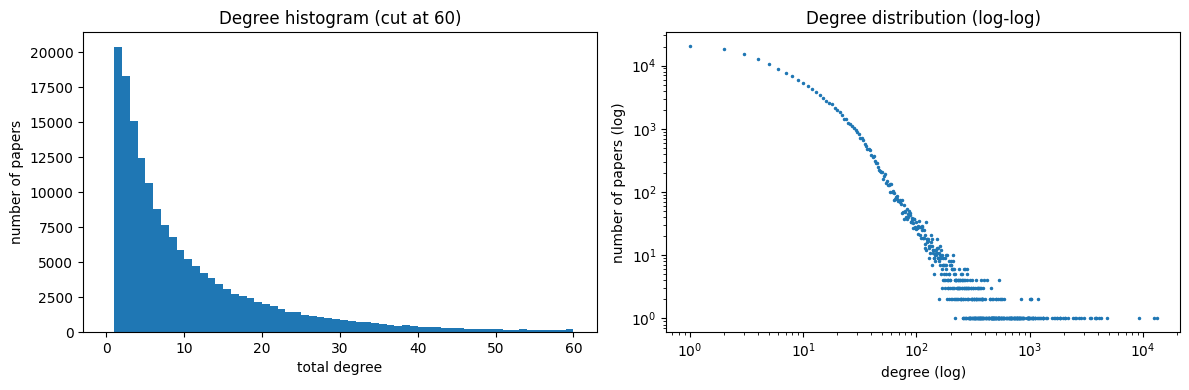

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(total_degree, bins=60, range=(0, 60))
axes[0].set_xlabel("total degree")
axes[0].set_ylabel("number of papers")
axes[0].set_title("Degree histogram (cut at 60)")

# log-log plot: good way to see if a few nodes have very high degree
values, counts = np.unique(total_degree[total_degree > 0], return_counts=True)
axes[1].loglog(values, counts, marker=".", linestyle="none", markersize=3)
axes[1].set_xlabel("degree (log)")
axes[1].set_ylabel("number of papers (log)")
axes[1].set_title("Degree distribution (log-log)")

plt.tight_layout()
plt.show()

**What we see:** most papers have a small degree. A few papers (surveys, famous papers) have a
very large degree. This is normal for real-world networks.

## Isolated nodes

An **isolated node** has degree 0 — no edges at all.
For a GNN this is a problem: such a node has no neighbours, so the graph cannot help it.

In [21]:
n_isolated = int((total_degree == 0).sum())
print("Papers with no edges at all:", n_isolated,
      f"({100 * n_isolated / num_nodes:.3f} %)")
print("Papers that nobody cites   :", f"{int((in_degree == 0).sum()):,}")
print("Papers that cite nobody    :", f"{int((out_degree == 0).sum()):,}")

Papers with no edges at all: 0 (0.000 %)
Papers that nobody cites   : 62,006
Papers that cite nobody    : 17,440


## Is the graph connected?

Two useful ideas:

- **Weakly connected**: we forget the arrow direction and ask "can I walk from A to B?"
- **Strongly connected**: we follow the arrows and ask "can I walk from A to B *and* back?"

In a citation graph, strong connection is rare. Citations point to the past, so you cannot usually
come back.

### A short note on NetworkX

NetworkX is the most common Python library for graphs.

- `nx.Graph` = graph without direction
- `nx.DiGraph` = graph with direction
- it has functions for nodes, edges, degree and connected components

But NetworkX stores everything in Python dictionaries. For our graph (169k nodes, 1.1M edges) this
would use several GB of memory and be slow on Colab.

So we do this:

- use NetworkX on a **tiny example** to learn the idea
- use **SciPy** on the real graph, because it is fast and uses little memory

In [22]:
import networkx as nx

# Tiny example with 5 nodes
small = nx.DiGraph()
small.add_edges_from([(0, 1), (1, 2), (2, 0), (3, 4)])

print("nodes:", list(small.nodes()))
print("edges:", list(small.edges()))
print("out-degree of node 0:", small.out_degree(0))
print()
print("weakly connected parts  :", [sorted(c) for c in nx.weakly_connected_components(small)])
print("strongly connected parts:", [sorted(c) for c in nx.strongly_connected_components(small)])
print()
print("Nodes 0,1,2 form a circle, so they are strongly connected.")
print("Nodes 3,4 are joined only one way, so each one is its own strong part.")

nodes: [0, 1, 2, 3, 4]
edges: [(0, 1), (1, 2), (2, 0), (3, 4)]
out-degree of node 0: 1

weakly connected parts  : [[0, 1, 2], [3, 4]]
strongly connected parts: [[0, 1, 2], [4], [3]]

Nodes 0,1,2 form a circle, so they are strongly connected.
Nodes 3,4 are joined only one way, so each one is its own strong part.


In [23]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# Build a sparse matrix: put a 1 at position (u, v) for every edge
adj = coo_matrix((np.ones(num_edges, dtype=np.int8), (source, target)),
                 shape=(num_nodes, num_nodes)).tocsr()

n_weak, weak_labels = connected_components(adj, directed=True, connection="weak")
n_strong, strong_labels = connected_components(adj, directed=True, connection="strong")

weak_sizes = np.bincount(weak_labels)
strong_sizes = np.bincount(strong_labels)

print("Weakly connected parts  :", f"{n_weak:,}")
print("  biggest one has       :", f"{weak_sizes.max():,}", "papers",
      f"({100 * weak_sizes.max() / num_nodes:.1f} %)")
print()
print("Strongly connected parts:", f"{n_strong:,}")
print("  biggest one has       :", f"{strong_sizes.max():,}", "papers")

Weakly connected parts  : 1
  biggest one has       : 169,343 papers (100.0 %)

Strongly connected parts: 141,223
  biggest one has       : 23,164 papers


**What this means:** if we ignore direction, the whole dataset is one big connected blob.
If we follow the arrows, the graph breaks into a very large number of parts, and most of them are
just a single paper.

This is important for the experiment notebook. If we keep the arrows, a brand-new paper (which nobody has cited
yet) receives **no messages** from its neighbours. Since our test papers are the newest ones, that
would hurt us a lot.

So in the experiment notebook we will make the graph **undirected** (add the reverse of every edge). We will
write this down clearly there.

## Density

**Density** = how many edges exist, divided by how many edges could exist.

In [24]:
possible_edges = num_nodes * (num_nodes - 1)
density = num_edges / possible_edges

print("Possible edges:", f"{possible_edges:,}")
print("Real edges    :", f"{num_edges:,}")
print("Density       :", f"{density:.8f}")
print("Average degree:", round(float(total_degree.mean()), 2))

Possible edges: 28,676,882,306
Real edges    : 1,166,243
Density       : 0.00004067
Average degree: 13.77


**Why big graphs are sparse:** a paper can only cite a limited number of other papers, maybe 20 or
- It does not matter if arXiv has 1 million papers — the citation list does not grow with it.
So edges grow slowly, but *possible* edges grow very fast. The result is a very low density.

**Good news for us:** a GNN layer does work for each *edge*, not for each *pair of nodes*.
So the cost is about 1.1 million operations, not 28 billion. This is why we can train on one GPU.

## Homophily

**Homophily** = do connected nodes have the same label?

Here it means: does a paper usually cite papers from the **same subject**?

We calculate:

```
homophily = (number of edges where both papers have the same label) / (total edges)
```

We calculate it on the **undirected** graph, because that is what our models will use in the experiment notebook.

In [25]:
# Make the edge list undirected and remove repeats:
# for each edge we keep the pair (smaller id, bigger id), then take unique pairs.
small_id = np.minimum(source, target)
big_id = np.maximum(source, target)
not_self = small_id != big_id                       # drop self-loops

pair_keys = np.unique(small_id[not_self] * num_nodes + big_id[not_self])
print("Unique undirected edges:", f"{len(pair_keys):,}")

u = pair_keys // num_nodes                          # get back the two node ids
v = pair_keys % num_nodes

same_label = (y[u] == y[v])
homophily = float(same_label.mean())

print()
print("Edges where both papers have the SAME subject:", f"{int(same_label.sum()):,}")
print("Homophily:", round(homophily, 4))

Unique undirected edges: 1,157,799

Edges where both papers have the SAME subject: 757,455
Homophily: 0.6542


Is 0.65 a big number or a small number? We need something to compare with.

So we ask: if edges were placed **completely at random**, how often would two papers share a label?
That is just the chance of picking the same class twice.

In [26]:
class_share = class_counts / class_counts.sum()
random_homophily = float((class_share ** 2).sum())

print("Real homophily      :", round(homophily, 4))
print("Random homophily    :", round(random_homophily, 4))
print("Real is about", round(homophily / random_homophily, 1), "times higher than random")

Real homophily      : 0.6542
Random homophily    : 0.0771
Real is about 8.5 times higher than random


**What this means:** papers really do cite papers from their own subject much more often than
chance. So this graph has **high homophily**.

This is important for the experiment notebook. GNNs work by mixing information from neighbours. If neighbours
usually share your label, mixing is a good idea. If they did not, mixing could hurt.

**Careful:** this does not *prove* that homophily causes good accuracy. It only says the idea behind
GNNs fits this dataset well.

**Also careful:** homophily is not the same as connectivity. Connectivity asks "can I reach this
node?". Homophily asks "does my neighbour have my label?". They are different things.

## Do all nodes have the same homophily?

Not necessarily. Let us check if nodes with many neighbours behave differently from nodes with few.

In [27]:
# Each undirected edge gives information to both of its nodes, so we list both directions.
node_a = np.concatenate([u, v])
node_b = np.concatenate([v, u])
matches = (y[node_a] == y[node_b]).astype(float)

neighbours = np.bincount(node_a, minlength=num_nodes)
same_neighbours = np.bincount(node_a, weights=matches, minlength=num_nodes)

# local homophily = (same-label neighbours) / (all neighbours)
local_homophily = np.divide(same_neighbours, neighbours,
                            out=np.zeros(num_nodes), where=neighbours > 0)

bands = [(1, 2), (2, 5), (5, 10), (10, 25), (25, 100), (100, 10 ** 9)]
rows = []
for low, high in bands:
    mask = (neighbours >= low) & (neighbours < high)
    if mask.sum() == 0:
        continue
    name = f"{low}-{high - 1}" if high < 10 ** 9 else f"{low}+"
    rows.append({"neighbours": name, "papers": int(mask.sum()),
                 "avg local homophily": round(float(local_homophily[mask].mean()), 3)})
print(pd.DataFrame(rows).to_string(index=False))

neighbours  papers  avg local homophily
       1-1   20604                0.588
       2-4   46264                0.617
       5-9   39829                0.632
     10-24   42471                0.656
     25-99   18306                0.692
      100+    1869                0.648


So homophily is **not the same everywhere** in the graph. Some nodes have many neighbours from
other subjects.

This is interesting for our research question. GAT can give different weights to different
neighbours. GCN cannot. In theory GAT could ignore the "wrong" neighbours. Whether it really does is
what the experiment notebook will test.

## Summary — what we learned

- OGBN-Arxiv is **one big graph** of about 169,000 CS papers and 1.17 million citations.
- Each paper has **128 features** made from its title and abstract text.
- There are **40 subject classes**, and they are very **unbalanced**.
- The split is **by year**: train on old papers, test on new papers.
- The graph is **directed**, with almost no edges going both ways.
- Following the arrows, the graph breaks into very many small parts. So in the experiment notebook we will
   make the graph **undirected**.
- The graph is very **sparse** (average degree about 13.7). This is why training is affordable.
- **Homophily is about 0.65**, which is much higher than random (about 0.08). Papers usually
   cite their own subject.
- Homophily is **not the same for every node**. Some nodes have many neighbours from other subjects.

**Next:** The experiment notebook uses these facts to design and run the GCN vs GAT experiment.